In [ ]:
import scipy.io as sio

data = sio.loadmat("../DB2_s1/S1_E1_A1.mat")

print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'emg', 'acc', 'stimulus', 'glove', 'inclin', 'subject', 'exercise', 'repetition', 'restimulus', 'rerepetition'])


In [40]:
for key in data:
    if not key.startswith("__"):
        print(key, data[key].shape)

emg (1808331, 12)
acc (1808331, 36)
stimulus (1808331, 1)
glove (1808331, 22)
inclin (1808331, 2)
subject (1, 1)
exercise (1, 1)
repetition (1808331, 1)
restimulus (1808331, 1)
rerepetition (1808331, 1)


In [41]:
emg = data["emg"]
restimulus = data["restimulus"].flatten()
rerepetition = data["rerepetition"].flatten()

print("EMG:", emg.shape)
print("Restimulus:", restimulus.shape)
print("Rerepetition:", rerepetition.shape)

EMG: (1808331, 12)
Restimulus: (1808331,)
Rerepetition: (1808331,)


In [42]:
import numpy as np

unique_labels, counts = np.unique(restimulus, return_counts=True)

for label, count in zip(unique_labels, counts):
    print("Label:", label, "Samples:", count)

Label: 0 Samples: 1064608
Label: 1 Samples: 78701
Label: 2 Samples: 58979
Label: 3 Samples: 50985
Label: 4 Samples: 45065
Label: 5 Samples: 40125
Label: 6 Samples: 25557
Label: 7 Samples: 58155
Label: 8 Samples: 28238
Label: 9 Samples: 39903
Label: 10 Samples: 45174
Label: 11 Samples: 43571
Label: 12 Samples: 44012
Label: 13 Samples: 39313
Label: 14 Samples: 37134
Label: 15 Samples: 23601
Label: 16 Samples: 44281
Label: 17 Samples: 40929


In [43]:
rerepetition = data["rerepetition"].flatten()

unique_rep, counts = np.unique(rerepetition, return_counts=True)

for rep, count in zip(unique_rep, counts):
    print("Repetition:", rep, "Samples:", count)

Repetition: 0 Samples: 3440
Repetition: 1 Samples: 313968
Repetition: 2 Samples: 295162
Repetition: 3 Samples: 297323
Repetition: 4 Samples: 300362
Repetition: 5 Samples: 296083
Repetition: 6 Samples: 301993


In [44]:
for movement in np.unique(restimulus):
    
    if movement == 0:
        continue
        
    reps = np.unique(rerepetition[restimulus == movement])
    
    print("Movement", movement, "repetitions:", reps)

Movement 1 repetitions: [1 2 3 4 5 6]
Movement 2 repetitions: [1 2 3 4 5 6]
Movement 3 repetitions: [1 2 3 4 5 6]
Movement 4 repetitions: [1 2 3 4 5 6]
Movement 5 repetitions: [1 2 3 4 5 6]
Movement 6 repetitions: [1 2 3 4 5 6]
Movement 7 repetitions: [1 2 3 4 5 6]
Movement 8 repetitions: [1 2 3 4 5 6]
Movement 9 repetitions: [1 2 3 4 5 6]
Movement 10 repetitions: [1 2 3 4 5 6]
Movement 11 repetitions: [1 2 3 4 5 6]
Movement 12 repetitions: [1 2 3 4 5 6]
Movement 13 repetitions: [1 2 3 4 5 6]
Movement 14 repetitions: [1 2 3 4 5 6]
Movement 15 repetitions: [1 2 3 4 5 6]
Movement 16 repetitions: [1 2 3 4 5 6]
Movement 17 repetitions: [1 2 3 4 5 6]


In [45]:
fs=2000
segment_length = 400   # 200 ms
step = 200              # 100 ms
nfft = 256
window_length = 256
overlap = 184

In [46]:
from scipy.signal import spectrogram
import matplotlib.pyplot as plt

channel = emg[:, 0]

segment = channel[0:400]

f, t, Sxx = spectrogram(
    segment,
    fs=fs,
    window="hamming",
    nperseg=256,
    noverlap=184,
    nfft=256
)

print("Spectrogram shape:", Sxx.shape)

Spectrogram shape: (129, 3)


In [47]:
Sxx_95 = Sxx[:95, :]
print(Sxx_95.shape)

(95, 3)


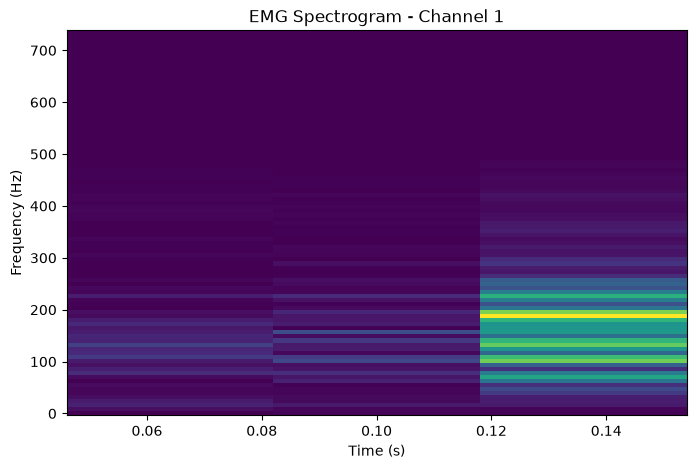

In [48]:
plt.figure(figsize=(8, 5))

plt.pcolormesh(
    t,
    f[:95],
    Sxx_95,
    shading="auto"
)

plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("EMG Spectrogram - Channel 1")

plt.show()

In [49]:
unique_labels = np.unique(restimulus)

print(unique_labels)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]


In [50]:
print("EMG shape:", emg.shape)

print("Movement labels:")
print(np.unique(restimulus))

print("Repetition labels:")
print(np.unique(rerepetition))

EMG shape: (1808331, 12)
Movement labels:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
Repetition labels:
[0 1 2 3 4 5 6]


In [51]:
movement = 1
repetition = 1

mask = (restimulus == movement) & (rerepetition == repetition)

movement_emg = emg[mask]

print("Movement EMG shape:", movement_emg.shape)

Movement EMG shape: (14221, 12)


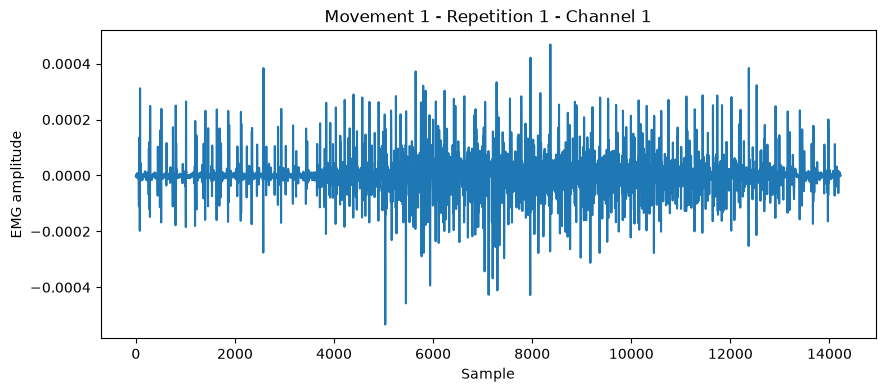

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.plot(movement_emg[:, 0])

plt.xlabel("Sample")
plt.ylabel("EMG amplitude")
plt.title("Movement 1 - Repetition 1 - Channel 1")

plt.show()

In [53]:
#segmentation of the movement EMG data into overlapping segments

segment_length = 400
step = 200

segments = []

for start in range(0, len(movement_emg) - segment_length + 1, step):
    
    segment = movement_emg[start:start + segment_length, :]
    
    segments.append(segment)

segments = np.array(segments)

print("Segments shape:", segments.shape)

Segments shape: (70, 400, 12)


In [54]:
#calculating the spectrogram of the first segment of each channel

segment = segments[0]
from scipy.signal import spectrogram

spectrograms = []

for ch in range(12):
    
    f, t, Sxx = spectrogram(
        segment[:, ch],
        fs=2000,
        window="hamming",
        nperseg=256,
        noverlap=184,
        nfft=256
    )
    
    Sxx = Sxx[:95, :]
    
    spectrograms.append(Sxx)

spectrograms = np.array(spectrograms)

print("Spectrogram shape:", spectrograms.shape)

Spectrogram shape: (12, 95, 3)


In [55]:
feature_vector = spectrograms.flatten()

print("Feature vector shape:", feature_vector.shape)

Feature vector shape: (3420,)


In [56]:
#normalizing the spectrograms

normalized_spectrograms = []

for ch in range(12):

    S = spectrograms[ch]

    min_val = np.percentile(S, 1)
    max_val = np.percentile(S, 99)

    S_norm = (S - min_val) / (max_val - min_val)

    S_norm = np.clip(S_norm, 0, 1)

    normalized_spectrograms.append(S_norm)

normalized_spectrograms = np.array(normalized_spectrograms)

print("Normalized shape:", normalized_spectrograms.shape)

Normalized shape: (12, 95, 3)


In [57]:
print("Minimum:", normalized_spectrograms.min())
print("Maximum:", normalized_spectrograms.max())



Minimum: 0.0
Maximum: 1.0


In [58]:
feature_vector = normalized_spectrograms.flatten()

print("Feature vector shape:", feature_vector.shape)

Feature vector shape: (3420,)


In [59]:

import numpy as np
from scipy.signal import spectrogram

# Parameters
fs = 2000
segment_length = 400
step = 200
num_channels = 12

all_features = []
all_labels = []
all_repetitions = []

# Process each movement
for movement in range(1, 18):

    # Process repetitions 1 to 6
    for repetition in range(1, 7):

        # Select samples belonging to this movement and repetition
        mask = (
            (restimulus == movement) &
            (rerepetition == repetition)
        )

        movement_emg = emg[mask]

        # Skip if there is insufficient data
        if len(movement_emg) < segment_length:
            continue

        # Divide this movement into overlapping segments
        for start in range(
            0,
            len(movement_emg) - segment_length + 1,
            step
        ):
            segment = movement_emg[
                start:start + segment_length, :
            ]

            channel_features = []

            # Calculate spectrogram for each EMG channel
            for ch in range(num_channels):

                f, t, Sxx = spectrogram(
                    segment[:, ch],
                    fs=fs,
                    window="hamming",
                    nperseg=256,
                    noverlap=184,
                    nfft=256
                )

                # Keep the first 95 frequency bins
                Sxx = Sxx[:95, :]

                # Normalize each channel's spectrogram
                # This is a temporary per-segment version
                min_val = np.percentile(Sxx, 1)
                max_val = np.percentile(Sxx, 99)

                if max_val > min_val:
                    Sxx = (Sxx - min_val) / (max_val - min_val)
                else:
                    Sxx = np.zeros_like(Sxx)

                Sxx = np.clip(Sxx, 0, 1)

                channel_features.extend(Sxx.flatten())

            # Save the feature vector and its labels
            all_features.append(channel_features)
            all_labels.append(movement)
            all_repetitions.append(repetition)

# Convert lists into NumPy arrays
X = np.array(all_features)
y = np.array(all_labels)
repetitions = np.array(all_repetitions)

print("Feature matrix shape:", X.shape)
print("Movement labels shape:", y.shape)
print("Repetition labels shape:", repetitions.shape)
print("Unique movements:", np.unique(y))
print("Unique repetitions:", np.unique(repetitions))

Feature matrix shape: (3567, 3420)
Movement labels shape: (3567,)
Repetition labels shape: (3567,)
Unique movements: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
Unique repetitions: [1 2 3 4 5 6]


In [60]:

# Select training and testing repetitions
train_reps = [1, 3, 4, 6]
test_reps = [2, 5]

# Create masks
train_mask = np.isin(repetitions, train_reps)
test_mask = np.isin(repetitions, test_reps)

# Split features
X_train = X[train_mask]
X_test = X[test_mask]

# Split movement labels
y_train = y[train_mask]
y_test = y[test_mask]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training movements:", np.unique(y_train))
print("Testing movements:", np.unique(y_test))

Training features: (2392, 3420)
Testing features: (1175, 3420)
Training movements: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
Testing movements: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]


In [61]:

import numpy as np
from scipy.signal import spectrogram

fs = 2000
segment_length = 400
step = 200
num_channels = 12

# Store the unnormalized spectrograms and their labels
all_spectrograms = []
all_labels = []
all_repetitions = []

for movement in range(1, 18):
    for repetition in range(1, 7):

        mask = (
            (restimulus == movement) &
            (rerepetition == repetition)
        )

        movement_emg = emg[mask]

        for start in range(
            0, len(movement_emg) - segment_length + 1, step
        ):
            segment = movement_emg[start:start + segment_length, :]

            channel_spectrograms = []

            for ch in range(num_channels):
                f, t, Sxx = spectrogram(
                    segment[:, ch],
                    fs=fs,
                    window="hamming",
                    nperseg=256,
                    noverlap=184,
                    nfft=256
                )

                channel_spectrograms.append(Sxx[:95, :])

            # Shape: (12, 95, 3)
            all_spectrograms.append(
                np.array(channel_spectrograms)
            )
            all_labels.append(movement)
            all_repetitions.append(repetition)

# Convert to arrays
S_all = np.array(all_spectrograms)
y_all = np.array(all_labels)
rep_all = np.array(all_repetitions)

print("Spectrogram dataset shape:", S_all.shape)
print("Labels shape:", y_all.shape)
print("Repetitions shape:", rep_all.shape)

Spectrogram dataset shape: (3567, 12, 95, 3)
Labels shape: (3567,)
Repetitions shape: (3567,)


In [62]:
#splitting spectrograms into training and testing tests

# Repetitions used for training and testing
train_reps = [1, 3, 4, 6]
test_reps = [2, 5]

# Identify which segments belong to each set
train_mask = np.isin(rep_all, train_reps)
test_mask = np.isin(rep_all, test_reps)

# Split the raw spectrograms
S_train = S_all[train_mask]
S_test = S_all[test_mask]

# Split the movement labels
y_train = y_all[train_mask]
y_test = y_all[test_mask]

print("Training spectrograms:", S_train.shape)
print("Testing spectrograms:", S_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training spectrograms: (2392, 12, 95, 3)
Testing spectrograms: (1175, 12, 95, 3)
Training labels: (2392,)
Testing labels: (1175,)


In [63]:

# Make copies so the original spectrograms remain unchanged
S_train_norm = S_train.copy()
S_test_norm = S_test.copy()

# Store normalization limits for the 12 channels
lower_limits = np.zeros(12)
upper_limits = np.zeros(12)

for ch in range(12):

    # Learn limits from training data only
    lower_limits[ch] = np.percentile(S_train[:, ch, :, :], 1)
    upper_limits[ch] = np.percentile(S_train[:, ch, :, :], 99)

    # Normalize training and testing using the same limits
    if upper_limits[ch] > lower_limits[ch]:

        S_train_norm[:, ch, :, :] = (
            S_train[:, ch, :, :] - lower_limits[ch]
        ) / (upper_limits[ch] - lower_limits[ch])

        S_test_norm[:, ch, :, :] = (
            S_test[:, ch, :, :] - lower_limits[ch]
        ) / (upper_limits[ch] - lower_limits[ch])

    else:
        S_train_norm[:, ch, :, :] = 0
        S_test_norm[:, ch, :, :] = 0

# Clip values to the range [0, 1]
S_train_norm = np.clip(S_train_norm, 0, 1)
S_test_norm = np.clip(S_test_norm, 0, 1)

print("Normalized training shape:", S_train_norm.shape)
print("Normalized testing shape:", S_test_norm.shape)
print("Training minimum:", S_train_norm.min())
print("Training maximum:", S_train_norm.max())
print("Testing minimum:", S_test_norm.min())
print("Testing maximum:", S_test_norm.max())

Normalized training shape: (2392, 12, 95, 3)
Normalized testing shape: (1175, 12, 95, 3)
Training minimum: 0.0
Training maximum: 1.0
Testing minimum: 0.0
Testing maximum: 1.0


In [64]:

# Flatten each segment into one feature vector
X_train = S_train_norm.reshape(S_train_norm.shape[0], -1)
X_test = S_test_norm.reshape(S_test_norm.shape[0], -1)

print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training feature matrix: (2392, 3420)
Testing feature matrix: (1175, 3420)
Training labels: (2392,)
Testing labels: (1175,)


In [65]:

from sklearn.decomposition import PCA

# Create PCA with 100 components
pca = PCA(n_components=100)

# Learn the principal components using training data only
X_train_pca = pca.fit_transform(X_train)

# Apply the same PCA transformation to testing data
X_test_pca = pca.transform(X_test)

print("Training data after PCA:", X_train_pca.shape)
print("Testing data after PCA:", X_test_pca.shape)

print(
    "Total variance retained:",
    pca.explained_variance_ratio_.sum()
)

Training data after PCA: (2392, 100)
Testing data after PCA: (1175, 100)
Total variance retained: 0.7468739


In [66]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Create the SVM classifier
svm = SVC(kernel="rbf", C=1, gamma="scale")

# Train using training data only
svm.fit(X_train_pca, y_train)

print("SVM training completed!")

SVM training completed!


In [67]:

# Predict movement labels for the test data
y_pred = svm.predict(X_test_pca)

# Calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Test accuracy:", accuracy * 100, "%")

# Display performance for each movement
print(classification_report(y_test, y_pred))

Test accuracy: 72.25531914893617 %
              precision    recall  f1-score   support

           1       0.70      0.90      0.79       126
           2       0.78      0.59      0.67        98
           3       0.90      0.79      0.84        82
           4       0.74      0.74      0.74        68
           5       0.52      0.83      0.64        64
           6       1.00      0.92      0.96        39
           7       0.70      0.85      0.77        94
           8       0.50      0.87      0.63        45
           9       0.70      0.67      0.68        60
          10       0.63      0.54      0.58        68
          11       0.76      0.53      0.62        72
          12       0.68      0.70      0.69        69
          13       0.93      0.67      0.78        55
          14       0.88      0.55      0.68        65
          15       1.00      0.94      0.97        36
          16       0.68      0.54      0.60        74
          17       0.76      0.73      0.75   

In [68]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC

# Parameter ranges specified in the paper
C_values = [2.0**i for i in range(-5, 15)]
gamma_values = [2.0**j for j in range(-12, 8)]

param_grid = {
    "C": C_values,
    "gamma": gamma_values
}

# Four-fold cross-validation
cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# RBF SVM
svm = SVC(kernel="rbf")

grid_search = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Find the best parameters using training data only
grid_search.fit(X_train_pca, y_train)

print("Best parameters:", grid_search.best_params_)
print(
    "Best cross-validation accuracy:",
    grid_search.best_score_ * 100,
    "%"
)


Fitting 4 folds for each of 400 candidates, totalling 1600 fits
Best parameters: {'C': 8.0, 'gamma': 0.03125}
Best cross-validation accuracy: 78.05183946488295 %


In [69]:

from sklearn.metrics import accuracy_score, classification_report

# Get the best SVM model
best_svm = grid_search.best_estimator_

# Predict using the held-out test data
y_pred_tuned = best_svm.predict(X_test_pca)

# Calculate test accuracy
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Tuned SVM test accuracy:", tuned_accuracy * 100, "%")

# Detailed classification results
print(classification_report(y_test, y_pred_tuned))

Tuned SVM test accuracy: 75.74468085106383 %
              precision    recall  f1-score   support

           1       0.83      0.92      0.87       126
           2       0.77      0.73      0.75        98
           3       0.82      0.79      0.81        82
           4       0.76      0.71      0.73        68
           5       0.60      0.84      0.70        64
           6       0.95      0.95      0.95        39
           7       0.82      0.85      0.84        94
           8       0.61      0.93      0.74        45
           9       0.60      0.75      0.67        60
          10       0.74      0.51      0.61        68
          11       0.75      0.64      0.69        72
          12       0.70      0.68      0.69        69
          13       0.84      0.69      0.76        55
          14       0.81      0.65      0.72        65
          15       1.00      0.97      0.99        36
          16       0.65      0.64      0.64        74
          17       0.82      0.68   

In [75]:
print("Best parameters:", grid_search.best_params_)

print(
    "Best cross-validation accuracy:",
    grid_search.best_score_ * 100,
    "%"
)

print("Number of parameter combinations:", len(grid_search.cv_results_["params"]))

Best parameters: {'C': 8.0, 'gamma': 0.03125}
Best cross-validation accuracy: 78.05183946488295 %
Number of parameter combinations: 400


In [76]:
from sklearn.metrics import accuracy_score

best_svm = grid_search.best_estimator_

y_pred_full_grid = best_svm.predict(X_test_pca)

print(
    "Full-grid test accuracy:",
    accuracy_score(y_test, y_pred_full_grid) * 100,
    "%"
)

Full-grid test accuracy: 75.74468085106383 %


In [77]:
print("EMG shape:", emg.shape)
print("EMG minimum:", emg.min())
print("EMG maximum:", emg.max())
print("EMG mean:", emg.mean())
print("EMG standard deviation:", emg.std())

EMG shape: (1808331, 12)
EMG minimum: -0.005499916
EMG maximum: 0.00549807
EMG mean: -7.172665e-08
EMG standard deviation: 4.1796167e-05


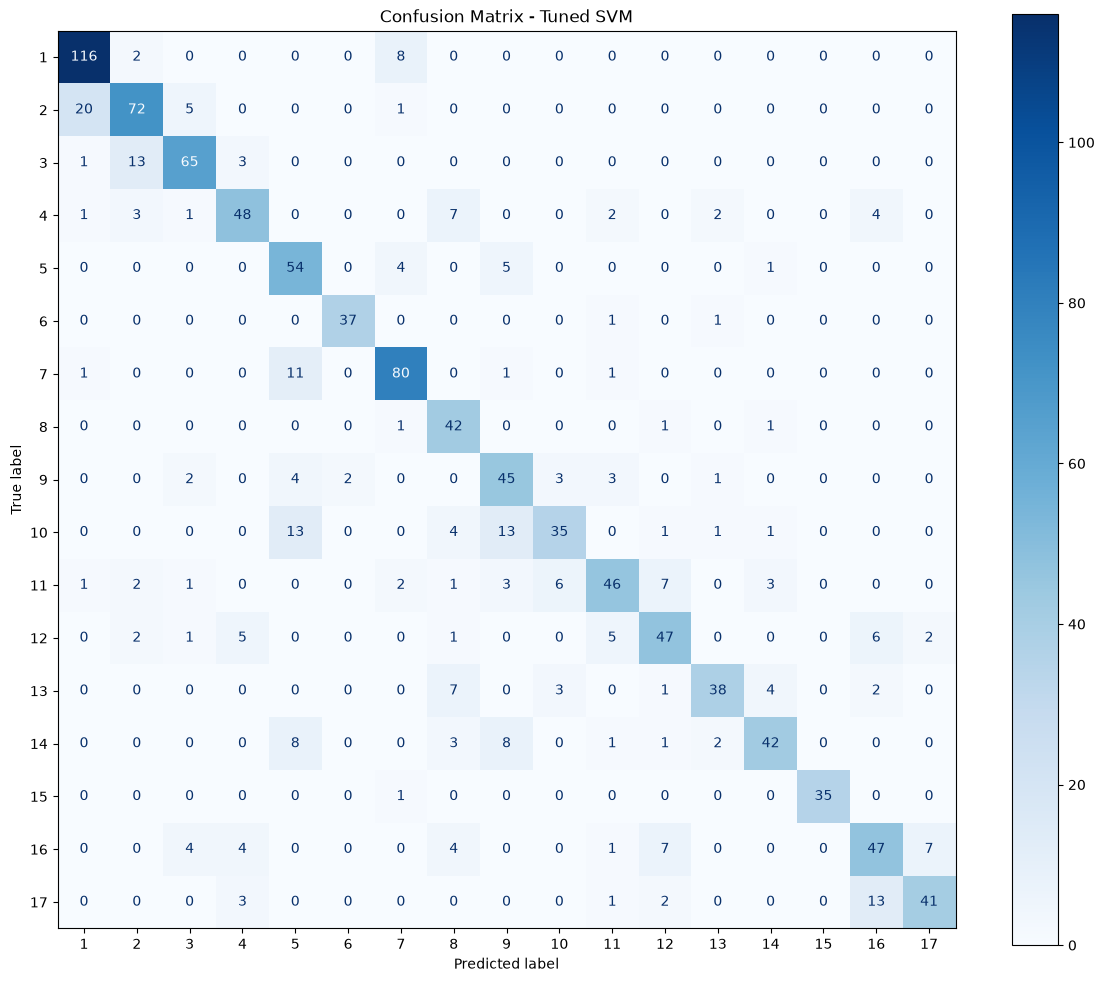

In [70]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix for the tuned SVM
cm = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=np.arange(1, 18)
)

# Plot confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(1, 18)
)

fig, ax = plt.subplots(figsize=(12, 10))
display.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Tuned SVM")
plt.tight_layout()
plt.show()

In [71]:
# Print the confusion matrix as numbers
print(cm)

[[116   2   0   0   0   0   8   0   0   0   0   0   0   0   0   0   0]
 [ 20  72   5   0   0   0   1   0   0   0   0   0   0   0   0   0   0]
 [  1  13  65   3   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  1   3   1  48   0   0   0   7   0   0   2   0   2   0   0   4   0]
 [  0   0   0   0  54   0   4   0   5   0   0   0   0   1   0   0   0]
 [  0   0   0   0   0  37   0   0   0   0   1   0   1   0   0   0   0]
 [  1   0   0   0  11   0  80   0   1   0   1   0   0   0   0   0   0]
 [  0   0   0   0   0   0   1  42   0   0   0   1   0   1   0   0   0]
 [  0   0   2   0   4   2   0   0  45   3   3   0   1   0   0   0   0]
 [  0   0   0   0  13   0   0   4  13  35   0   1   1   1   0   0   0]
 [  1   2   1   0   0   0   2   1   3   6  46   7   0   3   0   0   0]
 [  0   2   1   5   0   0   0   1   0   0   5  47   0   0   0   6   2]
 [  0   0   0   0   0   0   0   7   0   3   0   1  38   4   0   2   0]
 [  0   0   0   0   8   0   0   3   8   0   1   1   2  42   0   0   0]
 [  0 

In [72]:
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

indices = np.argsort(cm_no_diag.ravel())[::-1]

print("Largest misclassifications:")

count = 0

for idx in indices:
    true_class, predicted_class = np.unravel_index(idx, cm.shape)

    if cm_no_diag[true_class, predicted_class] == 0:
        break

    print(
        f"Actual movement {true_class + 1} predicted as "
        f"movement {predicted_class + 1}: "
        f"{cm_no_diag[true_class, predicted_class]} segments"
    )

    count += 1

    if count == 10:
        break

Largest misclassifications:
Actual movement 2 predicted as movement 1: 20 segments
Actual movement 3 predicted as movement 2: 13 segments
Actual movement 17 predicted as movement 16: 13 segments
Actual movement 10 predicted as movement 9: 13 segments
Actual movement 10 predicted as movement 5: 13 segments
Actual movement 7 predicted as movement 5: 11 segments
Actual movement 14 predicted as movement 5: 8 segments
Actual movement 1 predicted as movement 7: 8 segments
Actual movement 14 predicted as movement 9: 8 segments
Actual movement 16 predicted as movement 17: 7 segments


In [73]:

import numpy as np

movement = 1
repetition = 1

mask = (
    (restimulus == movement) &
    (rerepetition == repetition)
)

indices = np.where(mask)[0]

print("Total samples:", len(indices))

if len(indices) > 0:
    breaks = np.where(np.diff(indices) > 1)[0]

    print("Number of separate intervals:", len(breaks) + 1)

    starts = np.r_[indices[0], indices[breaks + 1]]
    ends = np.r_[indices[breaks], indices[-1]]

    for i in range(min(10, len(starts))):
        print(
            f"Interval {i + 1}: "
            f"start={starts[i]}, end={ends[i]}, "
            f"samples={ends[i] - starts[i] + 1}"
        )

Total samples: 14221
Number of separate intervals: 1
Interval 1: start=10826, end=25046, samples=14221


In [74]:

for movement in range(1, 18):
    for repetition in range(1, 7):

        mask = (
            (restimulus == movement) &
            (rerepetition == repetition)
        )

        indices = np.where(mask)[0]

        if len(indices) > 0:
            breaks = np.sum(np.diff(indices) > 1)

            if breaks > 0:
                print(
                    f"Movement {movement}, "
                    f"Repetition {repetition}: "
                    f"{breaks + 1} separate intervals"
                )

print("Interval check completed.")

Interval check completed.
